# Unsupervised Learning: Gaussian Mixture Model (GMM)

## 0. Setup and Configuration
Before training our Gaussian Mixture Model, we import the core scientific libraries and configure our data source. Use the code block below to either load your own dataset or default to a custom CSV file.

In [1]:
import numpy as np
import pandas as pd
import os

# --- Custom Dataset Configuration ---
# Configured with relative paths for seamless local VS Code and repo execution
USE_CUSTOM_DATA = True
DATASET_CANDIDATES = [
    os.path.join('..', 'datasets', 'student_performance.csv'),
    os.path.join('datasets', 'student_performance.csv'),
    'student_performance.csv',
    '/student_performance (1).csv'
]
DATASET_PATH = next((p for p in DATASET_CANDIDATES if os.path.exists(p)), DATASET_CANDIDATES[0])

if USE_CUSTOM_DATA:
    if os.path.exists(DATASET_PATH):
        # Load your dataset
        df_custom = pd.read_csv(DATASET_PATH)
        print(f"Loaded dataset from: {DATASET_PATH} with shape: {df_custom.shape}")
        display(df_custom.head())
    else:
        print(f"Warning: {DATASET_PATH} not found. Please verify dataset location.")
else:
    print("Using default synthetic data generator in Step 1.")


Loaded custom dataset with shape: (14003, 16)


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2


In [2]:
print("Available features in student dataset:")
print(list(df_custom.columns))

Available features in student dataset:
['StudyHours', 'Attendance', 'Resources', 'Extracurricular', 'Motivation', 'Internet', 'Gender', 'Age', 'LearningStyle', 'OnlineCourses', 'Discussions', 'AssignmentCompletion', 'ExamScore', 'EduTech', 'StressLevel', 'FinalGrade']


## 1. Training and Predicting
In this section, we generate synthetic data, instantiate the `GaussianMixture` model from `scikit-learn`, fit the model to find the underlying distributions, and predict the cluster assignments along with their soft membership probabilities (responsibilities).

In [3]:
import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture

# 1. Determine data source dynamically
if 'USE_CUSTOM_DATA' in globals() and USE_CUSTOM_DATA and 'df_custom' in globals():
    print("Using custom dataset configured in Step 0.")
    df = df_custom.copy()
    # Select relevant numeric features for student performance analysis
    X = df[["StudyHours", "ExamScore"]]
    if X.shape[1] < 2:
        raise ValueError("Custom dataset must contain at least 2 numerical features for this template.")
else:
    print("Using default synthetic data generator.")
    from sklearn.datasets import make_blobs
    X, y_true = make_blobs(n_samples=1000, centers=4, cluster_std=4, random_state=67)
    df = pd.DataFrame(X, columns=['Study_Hours', 'Grades'])

# 2. Define Gaussian Mixture Model parameters
n_components = 4
covariance_type = 'full' # Options: 'full', 'tied', 'diag', 'spherical'

# Instantiate and fit the GMM
gmm = GaussianMixture(
    n_components=n_components,
    covariance_type=covariance_type,
    random_state=42,
    max_iter=100
)
gmm.fit(X)

# 3. Predict cluster assignments (hard labeling) and posterior probabilities (soft labeling)
df['Cluster'] = gmm.predict(X)

# Get posterior probabilities (responsibilities) of each sample for each component
probs = gmm.predict_proba(X)

# Store membership/responsibility values for each cluster in our dataframe
for i in range(n_components):
    df[f'Probability_Cluster_{i}'] = probs[:, i]

# Save cluster means (centroids) for downstream steps
centroids = gmm.means_

display(df.head())

Using custom dataset configured in Step 0.


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,...,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade,Cluster,Probability_Cluster_0,Probability_Cluster_1,Probability_Cluster_2,Probability_Cluster_3
0,19,64,1,0,0,1,0,19,2,8,...,59,40,0,1,3,3,3.853895e-21,6.491118e-03,1.195490e-07,9.935088e-01
1,19,64,1,0,0,1,0,23,3,16,...,90,66,0,1,2,1,8.438341e-06,6.725458e-01,3.274439e-01,1.805799e-06
2,19,64,1,0,0,1,0,28,1,19,...,67,99,1,1,0,0,9.987110e-01,1.004679e-10,1.288956e-03,1.036838e-40
3,19,64,1,1,0,1,0,19,2,8,...,59,40,0,1,3,3,3.853895e-21,6.491118e-03,1.195490e-07,9.935088e-01
4,19,64,1,1,0,1,0,23,3,16,...,90,66,0,1,2,1,8.438341e-06,6.725458e-01,3.274439e-01,1.805799e-06


## 2. Inspecting Created Clusters
Here, we examine the resulting GMM properties, including estimated component means (centroids), the weights of each component, and the distribution of samples based on dominant assignments.

In [4]:
# 1. Inspect GMM cluster means (centroids)
centroids_df = pd.DataFrame(centroids, columns=["StudyHours", "ExamScore"])
centroids_df.index.name = 'Cluster'
print("--- GMM Component Means (Centroids) ---")
display(centroids_df)

# 2. Inspect the mixing weights of each Gaussian component
weights_df = pd.DataFrame(gmm.weights_, columns=['Weight'])
weights_df.index.name = 'Cluster'
print("--- GMM Component Weights ---")
display(weights_df)

# 3. Inspect size of each cluster based on hard (argmax) assignment
print("--- Sample Count per Dominant Cluster ---")
display(df['Cluster'].value_counts().sort_index().to_frame(name='Count'))

# 4. Inspect average posterior probability values to see how confident the model is
print("--- Average Posterior Probability per Cluster ---")
prob_cols = [f'Probability_Cluster_{i}' for i in range(n_components)]
display(df[prob_cols].mean().to_frame(name='Average Probability'))

--- GMM Component Means (Centroids) ---


,StudyHours,ExamScore
Cluster,,
0,20.116304,91.927806
1,19.955843,59.761207
2,19.888476,75.556504
3,19.976774,45.708716


--- GMM Component Weights ---


,Weight
Cluster,
0,0.282673
1,0.264177
2,0.263368
3,0.189782


--- Sample Count per Dominant Cluster ---


,Count
Cluster,
0,4006
1,3695
2,3632
3,2670


--- Average Posterior Probability per Cluster ---


,Average Probability
Probability_Cluster_0,0.280589
Probability_Cluster_1,0.267061
Probability_Cluster_2,0.265629
Probability_Cluster_3,0.186721


## 3. Visualizing the Results
We use `matplotlib` and `seaborn` to visualize the clusters along with their respective means (centroids).

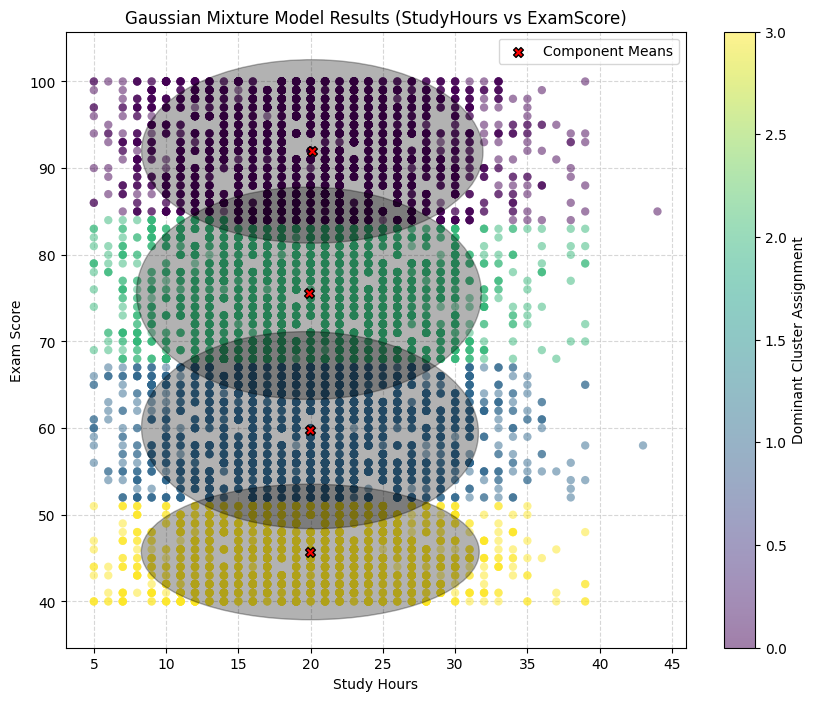

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np

def draw_ellipse(position, covariance, ax=None, **kwargs):
    """Draw an ellipse with a given position and covariance"""
    ax = ax or plt.gca()

    # Convert covariance to principal axes
    if covariance.shape == (2, 2):
        U, s, Vt = np.linalg.svd(covariance)
        angle = np.degrees(np.arctan2(U[1, 0], U[0, 0]))
        width, height = 2 * np.sqrt(s)
    else:
        angle = 0
        width, height = 2 * np.sqrt(covariance)

    # Draw the Ellipse (2-sigma boundary for ~95% confidence)
    for nsig in [2]:
        ax.add_patch(Ellipse(position, nsig * width, nsig * height,
                             angle=angle, **kwargs))

plt.figure(figsize=(10, 8))
ax = plt.gca()

# Plot data points colored by their dominant cluster
scatter = plt.scatter(
    df['StudyHours'],
    df['ExamScore'],
    c=df['Cluster'],
    cmap='viridis',
    alpha=0.5,
    edgecolors='none',
    zorder=2
)

# Plot GMM component means and covariances
for i in range(n_components):
    mean = gmm.means_[i]
    if covariance_type == 'full':
        covar = gmm.covariances_[i]
    elif covariance_type == 'tied':
        covar = gmm.covariances_
    elif covariance_type == 'diag':
        covar = np.diag(gmm.covariances_[i])
    elif covariance_type == 'spherical':
        covar = np.eye(gmm.means_.shape[1]) * gmm.covariances_[i]

    draw_ellipse(mean, covar, ax=ax, alpha=0.3, color='black', zorder=3)

# Plot GMM component means (centroids)
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c='red',
    s=50,
    marker='X',
    label='Component Means',
    edgecolors='black',
    linewidths=1,
    zorder=4
)

plt.title('Gaussian Mixture Model Results (StudyHours vs ExamScore)')
plt.xlabel('Study Hours')
plt.ylabel('Exam Score')
plt.colorbar(scatter, label='Dominant Cluster Assignment')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
# Save visualization to results directory
os.makedirs(os.path.join('..', 'results', 'gaussian_mixture'), exist_ok=True)
os.makedirs(os.path.join('results', 'gaussian_mixture'), exist_ok=True)
save_path = os.path.join('..', 'results', 'gaussian_mixture', 'gaussian_mixture_results.png') if os.path.exists(os.path.join('..', 'results')) else os.path.join('results', 'gaussian_mixture', 'gaussian_mixture_results.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {save_path}")
plt.show()

## 4. Interpretation Guide for the Results

When evaluating your Gaussian Mixture Model, keep the following points in mind:

*   **Soft vs. Hard Clustering:** GMM is a generative probabilistic model. Instead of hard boundaries (like K-Means) or purely distance-based fuzzy memberships, GMM assigns to each point the probability (posterior probability / responsibility) that it belongs to each Gaussian distribution.
*   **Covariance Type:** The `covariance_type` parameter defines the shape and orientation of the clusters.
    *   `spherical`: Clusters are spherical (features are independent with equal variance).
    *   `diag`: Cluster ellipsoids are parallel to the coordinate axes.
    *   `tied`: All clusters share the same general covariance shape.
    *   `full`: Each cluster can take any arbitrary ellipsoidal shape (highly flexible but requires more data to fit).
*   **Density Estimation:** Beyond clustering, GMM models the probability density function of the data. This allows it to generate new samples or perform anomaly detection (by identifying points in extremely low-density regions).

## 5. Component Profiles and Strategic Business Decisions

Based on the Gaussian Mixture Model component means and full covariance estimates ($K=4$), the cohort forms four probabilistic Gaussian distributions:

| Cluster | Cluster Label | Component Mean (StudyHours, ExamScore) | Mixing Weight | Dominant Count | Academic Profile |
| :---: | :---: | :---: | :---: | :---: | :--- |
| **0** | **Elite Achievers** | **(20.12, 91.93)** | 0.2827 | 4,006 (28.6%) | Highest probability of academic excellence; strong consistency around 92 score mark. |
| **1** | **Moderate / Low-Tier** | **(19.96, 59.76)** | 0.2642 | 3,695 (26.4%) | Scores concentrated near 60; substantial probability overlap with struggling tier. |
| **2** | **Competent / Solid** | **(19.89, 75.56)** | 0.2634 | 3,632 (25.9%) | Consistent passing and above-average performance; steady distribution with predictable outcomes. |
| **3** | **At-Risk / Critical** | **(19.98, 45.71)** | 0.1898 | 2,670 (19.1%) | Lowest mean exam performance (~46); critical support required. |

### Actionable Business & Institutional Decisions

#### Cluster 0: Elite Achievers
1. **Probabilistic Fellowship Allocation**: Allocate merit scholarships using GMM posterior responsibility scores ($P(C=0|X) > 0.90$) to objectively reward high-confidence top performers.
2. **Advanced Career & Graduate School Incubation**: Form an honors cohort that receives early research mentorship, corporate networking, and publication support.

#### Cluster 1: Moderate / Low-Tier
1. **Uncertainty-Aware Advisory Triaging**: Flag students with high entropy (equal probability between Cluster 1 and Cluster 3) for immediate advisor consultations to arrest further grade drop.
2. **Core Competency Reinforcement Modules**: Offer targeted mini-courses on core prerequisite mathematical and analytical competencies to move student scores above 70.

#### Cluster 2: Competent / Solid
1. **Performance Elevation Bootcamps**: Create targeted "Grade Leap" study circles designed to move students from 75 to 85+ by mastering complex exam case studies.
2. **Self-Paced Enrichment Electives**: Provide students with self-paced industry certifications (e.g., Python, Data Literacy) to maintain motivation and skill diversity.

#### Cluster 3: At-Risk / Critical
1. **Emergency Academic Intervention System**: Automatically enroll any student with $P(C=3|X) > 0.50$ into a comprehensive academic recovery program with mandatory tutoring hours.
2. **Holistic Support & Wellness Check-Ins**: Coordinate with student welfare and counseling services to address external impediments such as study fatigue, test anxiety, or socioeconomic stress.
